In [1]:
from concurrent.futures import ProcessPoolExecutor, as_completed
import csv
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
import os
import numpy as np
from typing import Tuple
from sixdrepnet import SixDRepNet
from concurrent.futures import ProcessPoolExecutor
import cv2
import numpy as np
import os
import re
import pandas as pd
import math
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

I0000 00:00:1792858609.224127   40541 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792858609.503965   40541 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792858610.704432   40541 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
db_folder = '../Photometric_DB'
total_cores = os.cpu_count() - 10

In [3]:
session_paths = []

for id in os.listdir(db_folder):
    if id.isdigit():
        id_path = os.path.join(db_folder, id)
        for session in os.listdir(id_path):
            session_path = os.path.join(id_path, session)
            if os.path.isdir(session_path):
                session_paths.append(session_path)

In [4]:
OUTPUT_BAD_POSE_SOLVE_PNP = '4_bad_pose_solve_pvp.txt'
OUTPUT_BAD_POSE_6DREPNET = '4_bad_pose_6drepnet.txt'
ERROR_LOG_SOLVE_PNP = '4_error_session_path_solve_pnp.csv'
ERROR_LOG_6DREPNET = '4_error_session_path_6drepnet.csv'
OUTPUT_BAD_YAW_6DREPNET = '4_bad_yaw_6drepnet.csv'
MAX_ANGLE_THRESHOLD = 25.0      # deg: ngưỡng coi là bad pose

# 1. Solve_PnP

In [5]:
def process_session(session_path):
    try:
        albedo_path = os.path.join(session_path, "albedo.png")
        metadata_path = os.path.join(session_path, "metadata.txt")

        if not os.path.isfile(metadata_path):
            _log_error_session_path(session_path, 'Không có metadata.txt')
            return

        if not os.path.isfile(albedo_path):
            _log_error_session_path(session_path, "Không có albedo.png")
            return

        # 1. Đọc metadata
        with open(metadata_path, "r", encoding="utf-8") as f:
            data = [float(x) for x in f.readline().split()]

        if len(data) < 22:
            _log_error_session_path(session_path, f'Metadata không đủ 22 giá trị: {len(data)}')
            return
        
        landmarks_2d = np.asarray(
            data[:22], dtype=np.float64
        ).reshape(11, 2)

        # 2. Đọc ảnh và kiểm tra
        img = cv2.imread(albedo_path, cv2.IMREAD_UNCHANGED)

        if img is None:
            _log_error_session_path(session_path, f"Không đọc được ảnh: {albedo_path}")
            return
        
        h, w = img.shape[:2]

        model_points = np.array([
            (-45.0,  40.0, -45.0),  # 0: Khóe ngoài mắt phải
            (-15.0,  40.0, -25.0),  # 1: Khóe trong mắt phải
            (  0.0,  42.0, -20.0),  # 2: Gốc mũi / vùng giữa hai mắt
            ( 15.0,  40.0, -25.0),  # 3: Khóe trong mắt trái
            ( 45.0,  40.0, -45.0),  # 4: Khóe ngoài mắt trái
            (-20.0,  10.0, -15.0),  # 5: Cánh mũi phải
            (  0.0,   0.0,   0.0),  # 6: Chóp mũi
            ( 20.0,  10.0, -15.0),  # 7: Cánh mũi trái
            (-30.0, -35.0, -30.0),  # 8: Khóe miệng phải
            ( 30.0, -35.0, -30.0),  # 9: Khóe miệng trái
            (  0.0, -75.0, -20.0),  # 10: Cằm
        ], dtype=np.float64)
        
        # 3. Loại các landmark được đánh dấu là (1, 1)
        valid_mask = ~np.all(landmarks_2d == [1, 1], axis=1)

        image_points = landmarks_2d[valid_mask]
        object_points = model_points[valid_mask]

        if len(image_points) < 6:
            _log_error_session_path(session_path, f"Chỉ có {len(image_points)} landmark hợp lệ; tạm yêu cầu ít nhất 6 điểm.")
            return
        
        # 4. Camera matrix giả định
        # Cần hiệu chuẩn thực tế để có góc pose đáng tin cậy hơn.
        focal_length = float(w)

        camera_matrix = np.array([
            [focal_length, 0, w / 2.0],
            [0, focal_length, h / 2.0],
            [0, 0, 1],
        ], dtype=np.float64)

        dist_coeffs = np.zeros((4, 1), dtype=np.float64)

        # 5. Ước lượng pose từ các cặp điểm đã lọc
        success, rvec, tvec = cv2.solvePnP(
            object_points,
            image_points,
            camera_matrix,
            dist_coeffs,
            flags=cv2.SOLVEPNP_EPNP,
        )

        if not success:
            _log_error_session_path(session_path, "cv2.solvePnP thất bại")
            return
        
        # 6. Chuyển rotation vector sang rotation matrix
        rmat, _ = cv2.Rodrigues(rvec)

        sy = np.sqrt(
            rmat[0, 0] ** 2 + rmat[1, 0] ** 2
        )
        singular = sy < 1e-6

        if not singular:
            x = np.arctan2(rmat[2, 1], rmat[2, 2])
            y = np.arctan2(-rmat[2, 0], sy)
            z = np.arctan2(rmat[1, 0], rmat[0, 0])
        else:
            x = np.arctan2(-rmat[1, 2], rmat[1, 1])
            y = np.arctan2(-rmat[2, 0], sy)
            z = 0.0

        pitch = float(np.degrees(x))
        yaw = float(np.degrees(y))
        roll = float(np.degrees(z))

        if pitch > 90:
            pitch -= 180
        elif pitch < -90:
            pitch += 180

        # 7. Tính sai số chiếu lại để kiểm tra chất lượng nghiệm
        projected, _ = cv2.projectPoints(
            object_points,
            rvec,
            tvec,
            camera_matrix,
            dist_coeffs,
        )

        projected = projected.reshape(-1, 2)
        errors = np.linalg.norm(projected - image_points, axis=1)
        rmse = float(np.sqrt(np.mean(errors ** 2)))

        # 8. Ghi kết quả
        pose_txt_path = os.path.join(
            session_path, "pose_solve_pnp.txt"
        )

        with open(pose_txt_path, "w", encoding="utf-8") as f:
            f.write("Head Pose Estimation (Euler Angles):\n")
            f.write(f"Roll (deg):  {roll:.2f}\n")
            f.write(f"Pitch (deg): {pitch:.2f}\n")
            f.write(f"Yaw (deg):   {yaw:.2f}\n")
            f.write(f"Valid landmarks: {len(image_points)}/11\n")
            f.write(f"Reprojection RMSE (px): {rmse:.2f}\n")

        if (
            abs(roll) > MAX_ANGLE_THRESHOLD
            or abs(pitch) > MAX_ANGLE_THRESHOLD
            or abs(yaw) > MAX_ANGLE_THRESHOLD
        ):
            with open(OUTPUT_BAD_POSE_SOLVE_PNP, "a", encoding="utf-8") as f:
                rel_path = os.path.relpath(session_path, db_folder)
                f.write(rel_path + "\n")

    except Exception as e:
        _log_error_session_path(session_path, repr(e))
        return
    
def _log_error_session_path(session_path, message):
    log_path = ERROR_LOG_SOLVE_PNP
    file_exists = os.path.isfile(log_path)

    with open(
        log_path,
        mode="a",
        newline="",
        encoding="utf-8",
    ) as f:
        writer = csv.writer(f)

        if not file_exists or os.path.getsize(log_path) == 0:
            writer.writerow(["session_path", "message"])

        writer.writerow([session_path, message])

In [6]:
with ProcessPoolExecutor(max_workers=total_cores) as executor:
    list(tqdm(executor.map(process_session, session_paths)))

3159it [00:02, 1458.17it/s]


Giải thích:
1. Đoạn code sử dụng phương pháp solvePnP giống của Minh để detect pose trên toàn bộ dataset và gen ra file `pose_solve_pnp` trong mỗi session của dataset. Các session lỗi sẽ được đưa vào file `4_error_session_path_solve_pnp`
2. Tuy nhiên phương pháp này yêu cầu khai báo tọa độ 3d các điểm landmark của khuôn mặt mới có thể trả về ma trận quay chính xác. Do không thể ước lượng được tọa độ 3d của các điểm này (đã thử dùng deep map tái tạo lại nhưng ko hiểu hệ tọa độ) nên code khai báo một ma trận 3d chung cho toàn bộ session để ước lượng pose. Hiển nhiên mọi khuôn mặt không thể có cùng 1 model 3d landmarks nên cách này ước lượng pose sai số rất lớn.

# 2. 6DRepNet

In [7]:
model = None

def init_worker():
    global model
    model = SixDRepNet()

In [8]:
def process_session(session_path):
    try:
        albedo_path = os.path.join(session_path, "albedo_crop.png")

        if not os.path.isfile(albedo_path):
            _log_error_session_path(session_path, "Không có albedo_crop.png")
            return

        img = cv2.imread(albedo_path)

        if img is None:
            _log_error_session_path(session_path, f"Không đọc được ảnh: {albedo_path}")
            return
        
        pitch, yaw, roll = model.predict(img)

        # Chuyển về scalar float
        pitch = float(np.asarray(pitch).reshape(-1)[0])
        yaw   = float(np.asarray(yaw).reshape(-1)[0])
        roll  = float(np.asarray(roll).reshape(-1)[0])

        pose_txt_path = os.path.join(
            session_path, "pose_6drepnet.txt"
        )

        with open(pose_txt_path, "w", encoding="utf-8") as f:
            f.write("Head Pose Estimation (Euler Angles):\n")
            f.write(f"Roll (deg):  {roll:.2f}\n")
            f.write(f"Pitch (deg): {pitch:.2f}\n")
            f.write(f"Yaw (deg):   {yaw:.2f}\n")

        if (
            abs(roll) > MAX_ANGLE_THRESHOLD
            or abs(pitch) > MAX_ANGLE_THRESHOLD
            or abs(yaw) > MAX_ANGLE_THRESHOLD
        ):
            with open(OUTPUT_BAD_POSE_6DREPNET, "a", encoding="utf-8") as f:
                rel_path = os.path.relpath(session_path, db_folder)
                f.write(rel_path + "\n")

    except Exception as e:
        _log_error_session_path(session_path, repr(e))
        return
    
def _log_error_session_path(session_path, message):
    log_path = ERROR_LOG_6DREPNET
    file_exists = os.path.isfile(log_path)

    with open(
        log_path,
        mode="a",
        newline="",
        encoding="utf-8",
    ) as f:
        writer = csv.writer(f)

        if not file_exists or os.path.getsize(log_path) == 0:
            writer.writerow(["session_path", "message"])

        writer.writerow([session_path, message])

In [9]:
with ProcessPoolExecutor(max_workers=total_cores, initializer=init_worker) as executor:
    list(tqdm(executor.map(process_session, session_paths)))

3159it [02:17, 22.89it/s]


In [10]:
def read_pose_file(pose_path):
    result = {
        "yaw": np.nan,
        "pitch": np.nan,
        "roll": np.nan,
    }

    if not os.path.isfile(pose_path):
        return result

    with open(pose_path, "r", encoding="utf-8") as f:
        content = f.read()

    for angle in ("yaw", "pitch", "roll"):
        pattern = rf"{angle}\s*\(deg\)\s*:\s*([-+]?\d+(?:\.\d+)?)"
        match = re.search(pattern, content, flags=re.IGNORECASE)

        if match:
            result[angle] = float(match.group(1))

    return result


# =========================
# Đọc danh sách session
# =========================
with open(OUTPUT_BAD_POSE_6DREPNET, "r", encoding="utf-8") as f:
    bad_pose_session_paths = [
        line.strip()
        for line in f
        if line.strip()
    ]

# Loại bỏ đường dẫn trùng nếu có
bad_pose_session_paths = list(dict.fromkeys(bad_pose_session_paths))

# =========================
# Đọc pose của từng session
# =========================
rows = []

for bad_pose_session_path in bad_pose_session_paths:
    pose_path = os.path.join(
        db_folder, bad_pose_session_path, "pose_6drepnet.txt"
    )

    pose = read_pose_file(pose_path)

    rows.append({
        "id": bad_pose_session_path.split("/")[0],
        "session": bad_pose_session_path.split("/")[1],
        "yaw": pose["yaw"],
        "pitch": pose["pitch"],
        "roll": pose["roll"],
        "max_abs_angle": np.nanmax(
            np.abs([
                pose["yaw"],
                pose["pitch"],
                pose["roll"]
            ])
        ) if not np.isnan([
            pose["yaw"],
            pose["pitch"],
            pose["roll"]
        ]).all() else np.nan,
        "pose_file_exists": os.path.isfile(pose_path),
    })

df = pd.DataFrame(rows)

print(f"Tổng số session trong danh sách: {len(df)}")
print(f"Số session có file pose: {df['pose_file_exists'].sum()}")
print(f"Số session thiếu file pose: {(~df['pose_file_exists']).sum()}")

Tổng số session trong danh sách: 66
Số session có file pose: 66
Số session thiếu file pose: 0


In [11]:
df.describe()

,yaw,pitch,roll,max_abs_angle
count,66.000000,66.000000,66.000000,66.000000
mean,-7.605455,-6.900909,0.634697,34.474848
std,34.013158,15.370996,11.282553,10.248204
min,-69.820000,-39.920000,-24.090000,25.150000
25%,-33.547500,-16.062500,-5.627500,27.080000
50%,-26.295000,-7.440000,-1.355000,30.565000
75%,27.222500,-1.160000,6.315000,36.737500
max,58.750000,33.000000,36.950000,69.820000


In [12]:
# filtered_df = df[
#     (df["max_abs_angle"] > 25) &
#     (df["max_abs_angle"] < 30)
# ].copy()

# Chỉ hiển thị ID và session
# display(filtered_df[["id", "session", "max_abs_angle"]])

filtered_df = df

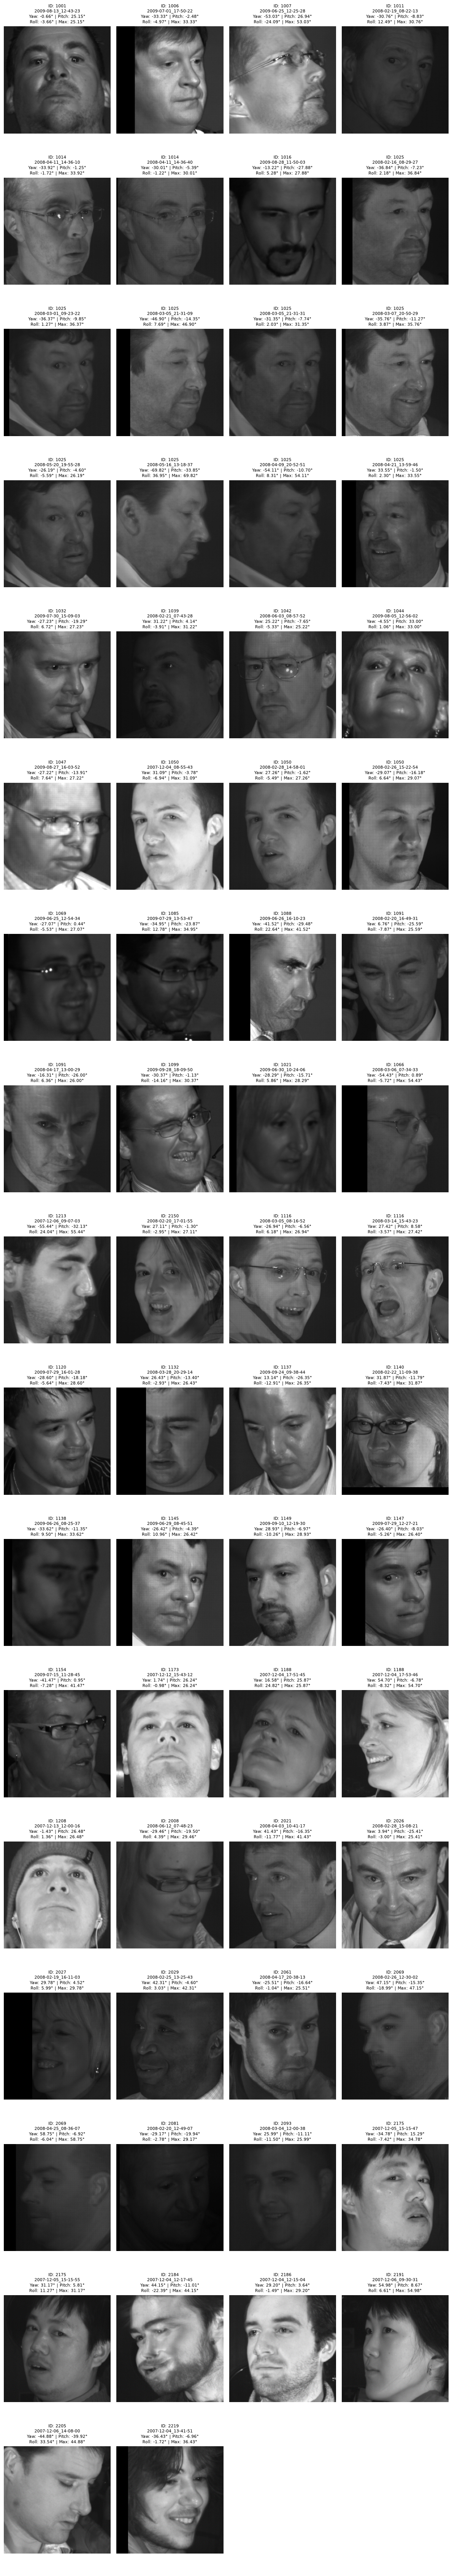

In [13]:
# Số ảnh tối đa mỗi dòng
MAX_COLS = 4

n_images = len(filtered_df)

if n_images == 0:
    print("Không có ảnh nào trong filtered_df.")
else:
    n_cols = min(MAX_COLS, n_images)
    n_rows = math.ceil(n_images / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(3 * n_cols, 4 * n_rows),
        squeeze=False
    )

    # Tắt tất cả subplot trước để ẩn các ô thừa
    for ax in axes.flat:
        ax.axis("off")

    for i, (_, row) in enumerate(filtered_df.iterrows()):
        ax = axes.flat[i]

        # Đường dẫn ảnh
        img_path = os.path.join(
            db_folder,
            str(row["id"]),
            str(row["session"]),
            "albedo_crop.png"
        )

        # Đọc ảnh
        img = cv2.imread(img_path)

        if img is None:
            ax.set_title(
                f'{row["id"]}/{row["session"]}\nKhông đọc được ảnh',
                fontsize=8
            )
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Hiển thị ảnh
        ax.imshow(img)
        ax.axis("off")

        # Tiêu đề gồm ID, session và 3 góc pose
        ax.set_title(
            f'ID: {row["id"]}\n'
            f'{row["session"]}\n'
            f'Yaw: {row["yaw"]:.2f}° | '
            f'Pitch: {row["pitch"]:.2f}°\n'
            f'Roll: {row["roll"]:.2f}° | '
            f'Max: {row["max_abs_angle"]:.2f}°',
            fontsize=8
        )

    plt.tight_layout()
    plt.show()


Giải thích
1. Đoạn code triển khai model 6drepnet để detect pose của khuôn mặt trên toàn bộ session của dataset. Với mỗi session sẽ sinh ra file `pose_6drepnet.txt` chứa thông tin 3 góc detect được. Các session lỗi không detect được sẽ được ghi vào file `4_error_session_path_6drepnet.csv`. Với các session có góc pose bất kỳ nào lớn hơn 25 sẽ được đưa vào `4_bad_pose_6drepnet.txt`
2. Mô hình detect rất xát với thực tế, sai số nhỏ. Tuy nhiên với các ảnh có yaw thực tế lớn (mất nửa mặt, quá nhiều chi tiết) thì detect đôi lúc không chính xác. Cần tiến hành loại bỏ

# 3. Loại bỏ các ảnh có yaw lớn

Các ảnh có góc yaw thực tế lớn (mất nửa mặt) thường bị detect sai => Loại bỏ

In [14]:
# 1. Khai báo Model Path và Options 
MODEL_PATH = 'face_landmarker.task'
base_options = python.BaseOptions(model_asset_path=MODEL_PATH)
options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    output_face_blendshapes=False,
    output_facial_transformation_matrixes=False,
    num_faces=1,
    min_face_detection_confidence=0.5,  
    min_face_presence_confidence=0.5
)

landmarker = None

def init_worker():
    global landmarker

    landmarker = vision.FaceLandmarker.create_from_options(options)

In [15]:
def process_session_detect_big_yaw(session_path):
    albedo_path = os.path.join(session_path, 'albedo_crop.png')
    img = cv2.imread(albedo_path, cv2.IMREAD_UNCHANGED)
    if img is None:
        _log_big_yaw_session_path(session_path, f'Không đọc được ảnh: {albedo_path}')
        return

    # Chuyển ảnh về uint8
    if img.dtype == np.uint16:
        # Tương đương ánh xạ dải 16-bit sang 8-bit
        image_uint8 = (img / 257).astype(np.uint8)
    elif img.dtype == np.uint8:
        image_uint8 = img.copy()
    else:
        _log_big_yaw_session_path(session_path, f'Kiểu dữ liệu PNG không được hỗ trợ: {img.dtype}')
        return
    
    # Chuẩn hóa số kênh thành RGB
    if image_uint8.ndim == 2:
        # Ảnh xám 1 kênh
        rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_GRAY2RGB)
    elif image_uint8.ndim == 3 and image_uint8.shape[2] == 3:
        # OpenCV đọc ảnh màu theo thứ tự BGR
        rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_BGR2RGB)
    elif image_uint8.ndim == 3 and image_uint8.shape[2] == 4:
        rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_BGRA2RGB)
    else:
        _log_big_yaw_session_path(session_path, f'Kích thước ảnh không được hỗ trợ: {image_uint8.shape}')
        return
    
    # Tạo ảnh đầu vào MediaPipe
    rgb_image = np.ascontiguousarray(rgb_image)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb_image
    )
    
    results = landmarker.detect(mp_image)
    
    # Các ảnh detect được 2 khuôn mặt trở nên thì index 0 là mặt chính 
    # Các ảnh không detect được khuôn mặt đã có pose_6drepnet đúng không cần quan tâm
    if not results.face_landmarks:
        return
    
    face_landmarks = results.face_landmarks[0]
    h, w = rgb_image.shape[:2]
    
    # Chuyển đổi tọa độ pixel
    points = np.array(
        [(int(lm.x * w), int(lm.y * h)) for lm in face_landmarks], dtype=np.float64
    )
    
    # Lấy tọa độ các điểm mốc quan trọng để đo độ lệch/quay ngang:
    nose_tip = points[1]  # Chóp mũi
    left_cheek = points[234]  # Má/viền trái
    right_cheek = points[454]  # Má/viền phải
    
    # Tính khoảng cách từ chóp mũi đến má trái và má phải
    dist_left = np.linalg.norm(nose_tip - left_cheek)
    dist_right = np.linalg.norm(nose_tip - right_cheek)
    
    # Tránh lỗi chia cho 0
    if dist_right > 0 and dist_left > 0:
        # Tính tỷ lệ khoảng cách 2 bên
        ratio = max(dist_left, dist_right) / min(dist_left, dist_right)
    
        # Đặt ngưỡng (Threshold): Nếu tỷ lệ lớn hơn 2.5 hoặc 3.0 nghĩa là mặt quay ngang sâu / mất nửa mặt
        THRESHOLD_RATIO = 3
        if ratio > THRESHOLD_RATIO:
            _log_big_yaw_session_path(session_path, 'big yaw')
            return
    else:
        _log_big_yaw_session_path(session_path, 'dist_left and right = 0')
        return
      
def _log_big_yaw_session_path(session_path, message):
    log_path = OUTPUT_BAD_YAW_6DREPNET
    file_exists = os.path.isfile(log_path)

    with open(
        log_path,
        mode="a",
        newline="",
        encoding="utf-8",
    ) as f:
        writer = csv.writer(f)

        if not file_exists or os.path.getsize(log_path) == 0:
            writer.writerow(["session_path", "message"])

        writer.writerow([session_path, message])

In [16]:
with ProcessPoolExecutor(
    max_workers=total_cores,
    initializer=init_worker,
) as executor:
    list(
        tqdm(
            executor.map(process_session_detect_big_yaw, session_paths),
            total=len(session_paths),
        )
    )

W0000 00:00:1792858796.513433   41193 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792858796.519122   41199 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792858796.532019   41202 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792858796.532695   41199 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792858796.538689   41208 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792858796.550249   41208 inference_feedback_manager.cc:121] Feedback 

In [17]:
df_bad_yaw = pd.read_csv(OUTPUT_BAD_YAW_6DREPNET)

filtered_big_yaw = df_bad_yaw[
    df_bad_yaw["message"].eq("big yaw")
].copy()

# Loại bỏ session_path trùng lặp
filtered_big_yaw = filtered_big_yaw.drop_duplicates(
    subset=["session_path"]
)

rows = []

for _, row in filtered_big_yaw.iterrows():
    session_path = row["session_path"]

    pose_path = os.path.join(
        db_folder,
        session_path,
        "pose_6drepnet.txt"
    )

    pose = read_pose_file(pose_path)

    angles = np.array(
        [pose["yaw"], pose["pitch"], pose["roll"]],
        dtype=float
    )

    # Tách ID và tên session từ đường dẫn tương đối
    path_parts = session_path.strip("/").split("/")

    rows.append({
        "id": path_parts[2] if len(path_parts) > 0 else None,
        "session": path_parts[3] if len(path_parts) > 1 else None,
        "session_path": session_path,
        "message": row["message"],
        "yaw": pose["yaw"],
        "pitch": pose["pitch"],
        "roll": pose["roll"],
        "max_abs_angle": (
            np.nanmax(np.abs(angles))
            if not np.isnan(angles).all()
            else np.nan
        ),
        "pose_file_exists": os.path.isfile(pose_path),
    })

df_big_yaw = pd.DataFrame(rows)

# =========================
# Thống kê kết quả
# =========================
print(f"Tổng số session big yaw: {len(df_big_yaw)}")
print(
    f"Số session có file pose: "
    f"{df_big_yaw['pose_file_exists'].sum()}"
)
print(
    f"Số session thiếu file pose: "
    f"{(~df_big_yaw['pose_file_exists']).sum()}"
)

Tổng số session big yaw: 58
Số session có file pose: 58
Số session thiếu file pose: 0


In [18]:
df_big_yaw.describe()

,yaw,pitch,roll,max_abs_angle
count,58.000000,58.000000,58.000000,58.000000
mean,-4.984138,-3.503966,-0.740517,30.414655
std,31.431571,9.111078,9.254932,8.880287
min,-54.110000,-23.870000,-22.390000,18.270000
25%,-29.775000,-9.595000,-6.715000,23.792500
50%,-21.980000,-4.575000,-1.605000,29.000000
75%,27.380000,0.822500,6.132500,33.845000
max,58.750000,25.870000,24.820000,58.750000


In [19]:
filtered_df = df_big_yaw

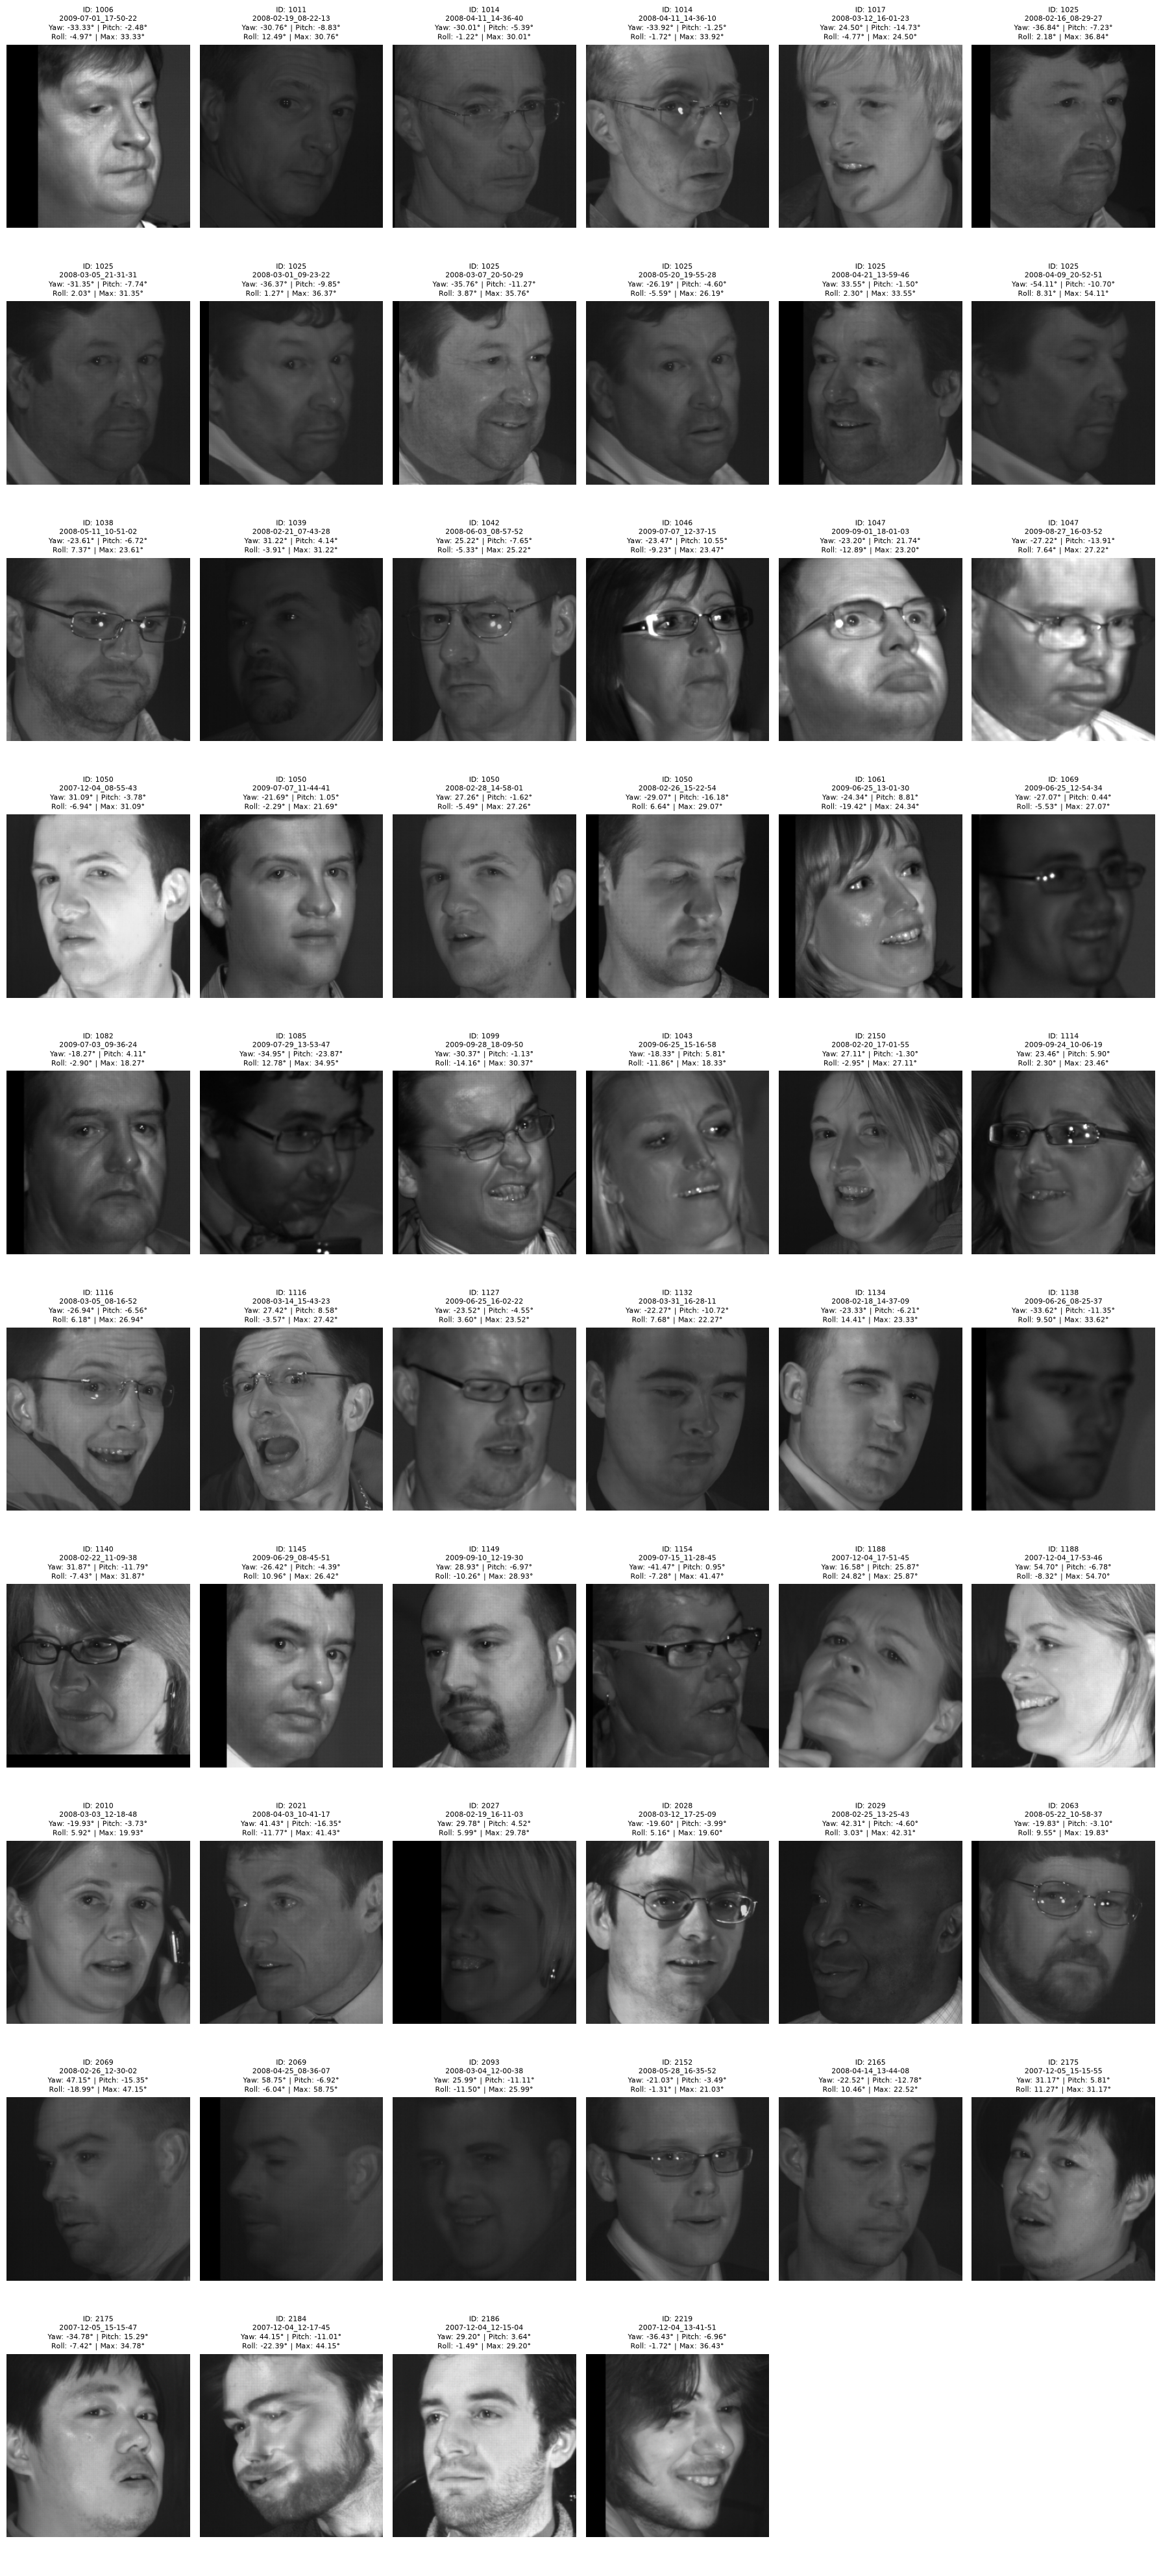

In [20]:
# Số ảnh tối đa mỗi dòng
MAX_COLS = 6

n_images = len(filtered_df)

if n_images == 0:
    print("Không có ảnh nào trong filtered_df.")
else:
    n_cols = min(MAX_COLS, n_images)
    n_rows = math.ceil(n_images / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(3 * n_cols, 4 * n_rows),
        squeeze=False
    )

    # Tắt tất cả subplot trước để ẩn các ô thừa
    for ax in axes.flat:
        ax.axis("off")

    for i, (_, row) in enumerate(filtered_df.iterrows()):
        ax = axes.flat[i]

        # Đường dẫn ảnh
        img_path = os.path.join(
            db_folder,
            str(row["id"]),
            str(row["session"]),
            "albedo_crop.png"
        )

        # Đọc ảnh
        img = cv2.imread(img_path)

        if img is None:
            ax.set_title(
                f'{row["id"]}/{row["session"]}\nKhông đọc được ảnh',
                fontsize=8
            )
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Hiển thị ảnh
        ax.imshow(img)
        ax.axis("off")

        # Tiêu đề gồm ID, session và 3 góc pose
        ax.set_title(
            f'ID: {row["id"]}\n'
            f'{row["session"]}\n'
            f'Yaw: {row["yaw"]:.2f}° | '
            f'Pitch: {row["pitch"]:.2f}°\n'
            f'Roll: {row["roll"]:.2f}° | '
            f'Max: {row["max_abs_angle"]:.2f}°',
            fontsize=8
        )

    plt.tight_layout()
    plt.show()


Giải thích
1. Dùng mediapipe để xác định các điểm chóp mũi (1), viền má/tai trái (234), viền má tai phải (454) và tính khoảng cách euclude 2D từ chóp mũi tới 2 điểm trên. ratio = max(dist) / min(dist)
2. Qua kiểm tra, thấy khi ratio = 3 có thể lọc ra các sessoin có pose yaw lớn cần loại bỏ.

# 4. Final remove session

In [21]:
def read_pose_file(pose_path):
    result = {
        "yaw": np.nan,
        "pitch": np.nan,
        "roll": np.nan,
    }

    if not os.path.isfile(pose_path):
        return result

    with open(pose_path, "r", encoding="utf-8") as f:
        content = f.read()

    for angle in ("yaw", "pitch", "roll"):
        pattern = rf"{angle}\s*\(deg\)\s*:\s*([-+]?\d+(?:\.\d+)?)"
        match = re.search(pattern, content, flags=re.IGNORECASE)

        if match:
            result[angle] = float(match.group(1))

    return result

In [22]:
df_bad_yaw = pd.read_csv(OUTPUT_BAD_YAW_6DREPNET)

filtered_big_yaw = df_bad_yaw[
    df_bad_yaw["message"].eq("big yaw")
].copy()

# Loại bỏ session_path trùng lặp
filtered_big_yaw = filtered_big_yaw.drop_duplicates(
    subset=["session_path"]
)

rows = []

for _, row in filtered_big_yaw.iterrows():
    session_path = row["session_path"]

    pose_path = os.path.join(
        db_folder,
        session_path,
        "pose_6drepnet.txt"
    )

    pose = read_pose_file(pose_path)

    angles = np.array(
        [pose["yaw"], pose["pitch"], pose["roll"]],
        dtype=float
    )

    # Tách ID và tên session từ đường dẫn tương đối
    path_parts = session_path.strip("/").split("/")

    rows.append({
        "id": path_parts[2] if len(path_parts) > 0 else None,
        "session": path_parts[3] if len(path_parts) > 1 else None,
        "session_path": session_path,
        "message": row["message"],
        "yaw": pose["yaw"],
        "pitch": pose["pitch"],
        "roll": pose["roll"],
        "max_abs_angle": (
            np.nanmax(np.abs(angles))
            if not np.isnan(angles).all()
            else np.nan
        ),
        "pose_file_exists": os.path.isfile(pose_path),
    })

df_big_yaw = pd.DataFrame(rows)

# =========================
# Thống kê kết quả
# =========================
print(f"Tổng số session big yaw: {len(df_big_yaw)}")
print(
    f"Số session có file pose: "
    f"{df_big_yaw['pose_file_exists'].sum()}"
)
print(
    f"Số session thiếu file pose: "
    f"{(~df_big_yaw['pose_file_exists']).sum()}"
)

Tổng số session big yaw: 58
Số session có file pose: 58
Số session thiếu file pose: 0


In [23]:
def read_pose_file(pose_path):
    result = {
        "yaw": np.nan,
        "pitch": np.nan,
        "roll": np.nan,
    }

    if not os.path.isfile(pose_path):
        return result

    with open(pose_path, "r", encoding="utf-8") as f:
        content = f.read()

    for angle in ("yaw", "pitch", "roll"):
        pattern = rf"{angle}\s*\(deg\)\s*:\s*([-+]?\d+(?:\.\d+)?)"
        match = re.search(pattern, content, flags=re.IGNORECASE)

        if match:
            result[angle] = float(match.group(1))

    return result


# =========================
# Đọc danh sách session
# =========================
with open(OUTPUT_BAD_POSE_6DREPNET, "r", encoding="utf-8") as f:
    bad_pose_session_paths = [
        line.strip()
        for line in f
        if line.strip()
    ]

# Loại bỏ đường dẫn trùng nếu có
bad_pose_session_paths = list(dict.fromkeys(bad_pose_session_paths))

# =========================
# Đọc pose của từng session
# =========================
rows = []

for bad_pose_session_path in bad_pose_session_paths:
    pose_path = os.path.join(
        db_folder, bad_pose_session_path, "pose_6drepnet.txt"
    )

    pose = read_pose_file(pose_path)

    rows.append({
        "id": bad_pose_session_path.split("/")[0],
        "session": bad_pose_session_path.split("/")[1],
        "yaw": pose["yaw"],
        "pitch": pose["pitch"],
        "roll": pose["roll"],
        "max_abs_angle": np.nanmax(
            np.abs([
                pose["yaw"],
                pose["pitch"],
                pose["roll"]
            ])
        ) if not np.isnan([
            pose["yaw"],
            pose["pitch"],
            pose["roll"]
        ]).all() else np.nan,
        "pose_file_exists": os.path.isfile(pose_path),
    })

df_bad_pose = pd.DataFrame(rows)

print(f"Tổng số session trong danh sách: {len(df_bad_pose)}")
print(f"Số session có file pose: {df_bad_pose['pose_file_exists'].sum()}")
print(f"Số session thiếu file pose: {(~df_bad_pose['pose_file_exists']).sum()}")

Tổng số session trong danh sách: 66
Số session có file pose: 66
Số session thiếu file pose: 0


In [24]:
df_bad_pose['session_path'] = '../Photometric_DB/' + df_bad_pose['id'] + '/' + df_bad_pose['session']

In [25]:
filtered_df = df_big_yaw[~df_big_yaw['session_path'].isin(df_bad_pose['session_path'])].copy()

In [26]:
# filtered_df = df[
#     (df["max_abs_angle"] > 25) &
#     (df["max_abs_angle"] < 30)
# ].copy()

# Chỉ hiển thị ID và session
# display(filtered_df[["id", "session", "max_abs_angle"]])

# filtered_df = gộp giữa pan

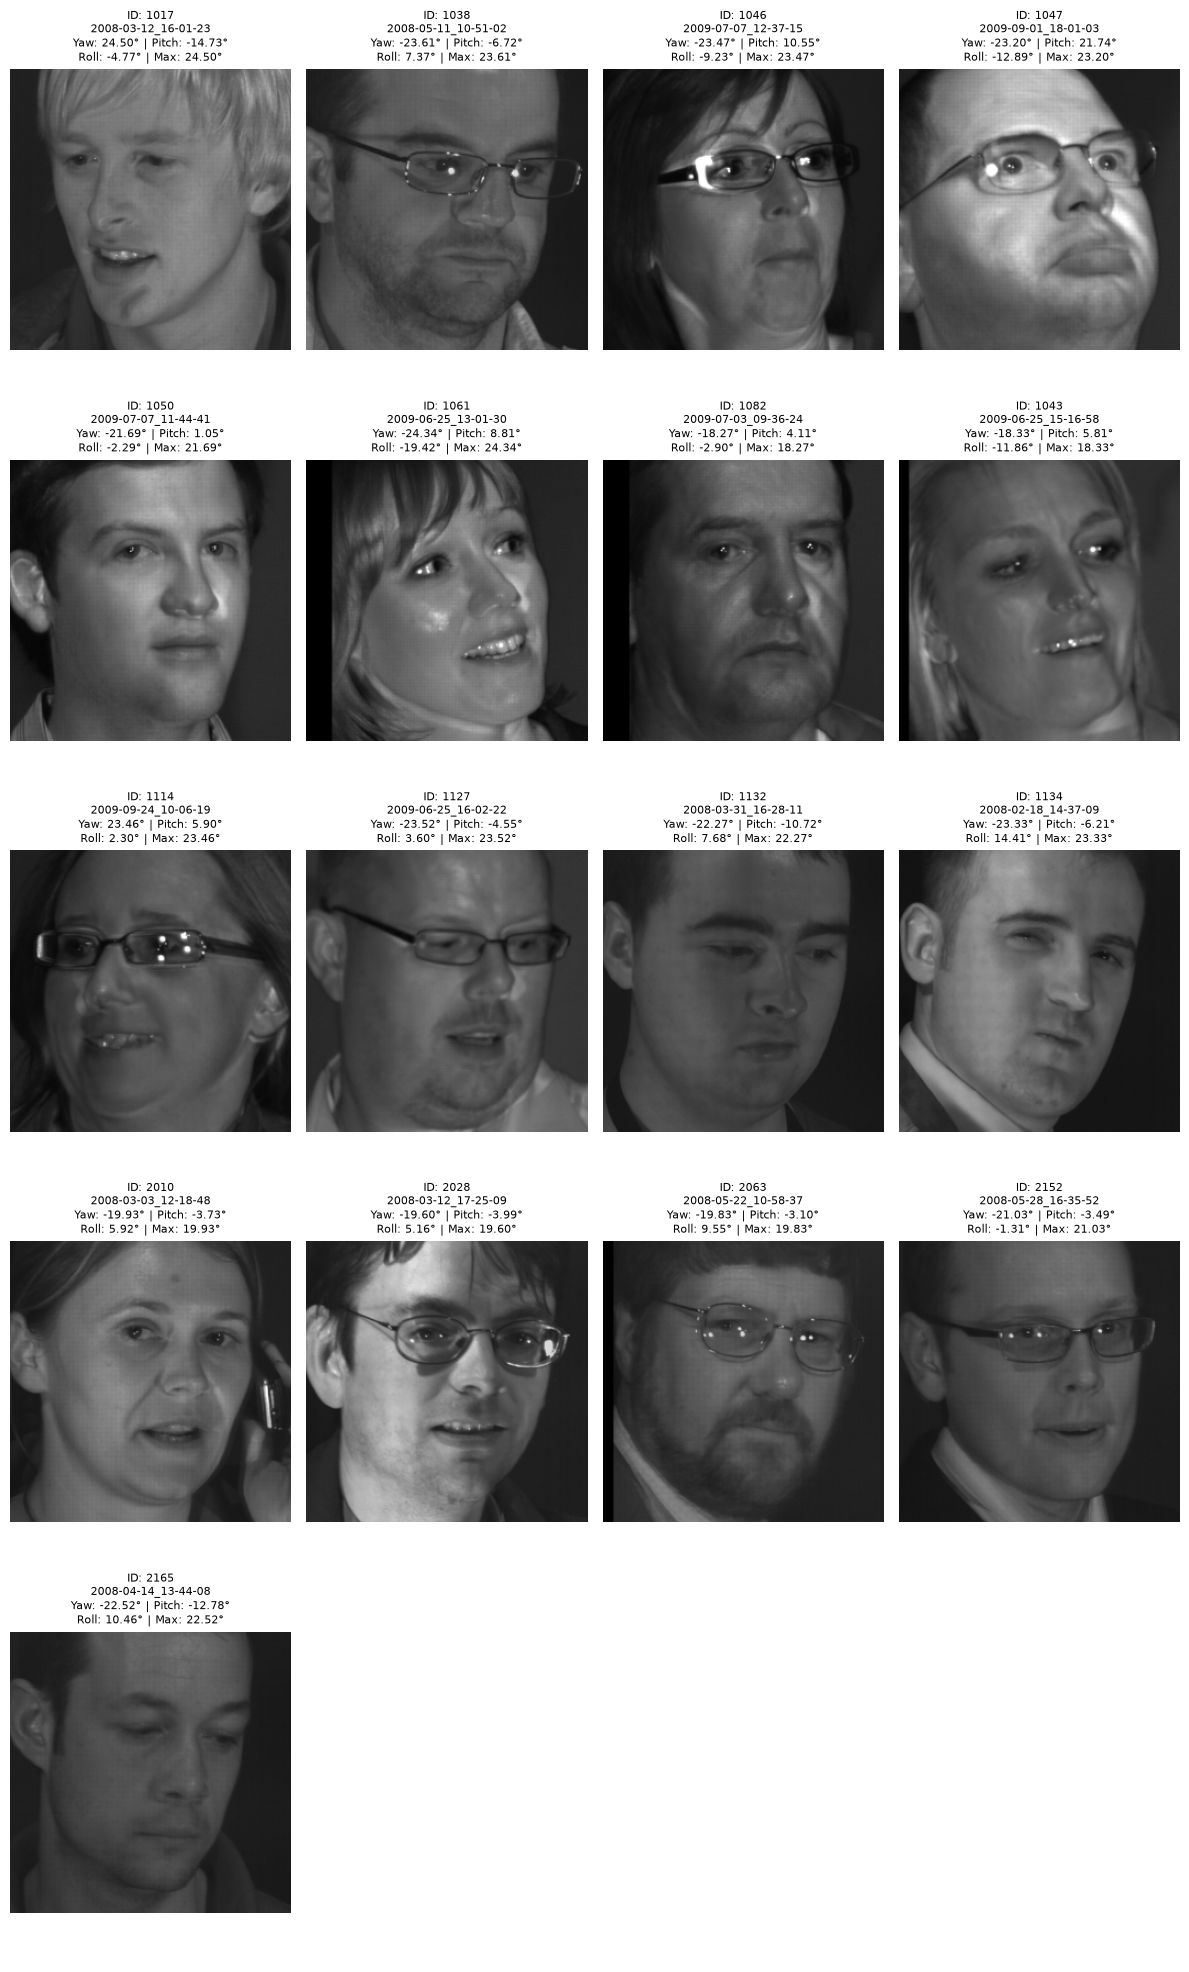

In [27]:
# Số ảnh tối đa mỗi dòng
MAX_COLS = 4

n_images = len(filtered_df)

if n_images == 0:
    print("Không có ảnh nào trong filtered_df.")
else:
    n_cols = min(MAX_COLS, n_images)
    n_rows = math.ceil(n_images / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(3 * n_cols, 4 * n_rows),
        squeeze=False
    )

    # Tắt tất cả subplot trước để ẩn các ô thừa
    for ax in axes.flat:
        ax.axis("off")

    for i, (_, row) in enumerate(filtered_df.iterrows()):
        ax = axes.flat[i]

        # Đường dẫn ảnh
        img_path = os.path.join(
            db_folder,
            str(row["id"]),
            str(row["session"]),
            "albedo_crop.png"
        )

        # Đọc ảnh
        img = cv2.imread(img_path)

        if img is None:
            ax.set_title(
                f'{row["id"]}/{row["session"]}\nKhông đọc được ảnh',
                fontsize=8
            )
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Hiển thị ảnh
        ax.imshow(img)
        ax.axis("off")

        # Tiêu đề gồm ID, session và 3 góc pose
        ax.set_title(
            f'ID: {row["id"]}\n'
            f'{row["session"]}\n'
            f'Yaw: {row["yaw"]:.2f}° | '
            f'Pitch: {row["pitch"]:.2f}°\n'
            f'Roll: {row["roll"]:.2f}° | '
            f'Max: {row["max_abs_angle"]:.2f}°',
            fontsize=8
        )

    plt.tight_layout()
    plt.show()


In [28]:
df_error_6drepnet = pd.read_csv(ERROR_LOG_6DREPNET)

In [29]:
df_bad_pose['session_path'] = df_bad_pose['session_path'].astype(str).str.strip()
df_error_6drepnet['session_path'] = df_error_6drepnet['session_path'].astype(str).str.strip()

In [30]:
df_error_6drepnet.head(10)

,session_path,message
0,../Photometric_DB/1025/2008-02-15_21-13-01,Không có albedo_crop.png
1,../Photometric_DB/1025/2008-03-06_15-01-06,Không có albedo_crop.png
2,../Photometric_DB/1025/2008-03-06_20-46-07,Không có albedo_crop.png
3,../Photometric_DB/1025/2008-03-06_20-46-32,Không có albedo_crop.png
4,../Photometric_DB/1025/2008-04-08_14-10-13,Không có albedo_crop.png
5,../Photometric_DB/1042/2008-04-16_09-14-29,Không có albedo_crop.png
6,../Photometric_DB/1050/2007-12-04_10-21-42,Không có albedo_crop.png
7,../Photometric_DB/1050/2007-12-04_10-21-56,Không có albedo_crop.png
8,../Photometric_DB/1050/2008-02-28_14-58-14,Không có albedo_crop.png
9,../Photometric_DB/1050/2007-12-11_13-57-24,Không có albedo_crop.png


In [31]:
df_bad_pose.head()

,id,session,yaw,pitch,roll,max_abs_angle,pose_file_exists,session_path
0,1001,2009-08-13_12-43-23,-0.66,25.15,-3.66,25.15,True,../Photometric_DB/1001/2009-08-13_12-43-23
1,1006,2009-07-01_17-50-22,-33.33,-2.48,-4.97,33.33,True,../Photometric_DB/1006/2009-07-01_17-50-22
2,1007,2009-06-25_12-25-28,-53.03,26.94,-24.09,53.03,True,../Photometric_DB/1007/2009-06-25_12-25-28
3,1011,2008-02-19_08-22-13,-30.76,-8.83,12.49,30.76,True,../Photometric_DB/1011/2008-02-19_08-22-13
4,1014,2008-04-11_14-36-10,-33.92,-1.25,-1.72,33.92,True,../Photometric_DB/1014/2008-04-11_14-36-10


In [32]:
all_removed_paths = pd.concat([
    df_bad_pose['session_path'], 
    df_error_6drepnet['session_path']
]).dropna().unique()

# 2. Lưu danh sách các session path vào file final_sesion_remove.txt (mỗi đường dẫn một dòng)
output_file = 'final_session_remove.txt'
with open(output_file, 'w', encoding='utf-8') as f:
    for path in all_removed_paths:
        f.write(f"{path}\n")

Giải thích
1. Sau khi xem xét các ảnh có yaw lớn (detect bằng media pipe), các ảnh có pose lớn (1 trong 3 pose detect mới 6drepnet > 25 độ) thì loại bỏ hết các session trong `4_bad_pose_6drepnet.txt` và `4_error_session_path_6drepnet.csv`
2. Các session được loại bỏ sẽ có đường dẫn trong file `final_session_remove.txt`